# Stage 2 (14–15 October): which subcomponents carry the emoticon update, and does the decomposition still explain it?

All numbers are read from committed result files. The notebook runs on a laptop in a few seconds and needs no GPU.

| Date | Run | Question | Report |
|---|---|---|---|
| 10-14 | lift test, round 2 | Does the decomposition stay faithful if we train its subcomponents, or if we translate a finished fine-tune onto them? | `reports/2026-10-14_analysis_lift-test.md` |
| 10-15 | identity test | How many subcomponents carry the update? Do they stay the same subcomponents? | `reports/2026-10-15_analysis_identity-test.md` |
| 10-15 | concentration test | Can training only a few subcomponents learn the behaviour? | `reports/2026-10-15_analysis_concentration-test.md` |
| 10-15 | amendment 1 | Do the trained subcomponents reproduce the behaviour if the masks are W₀'s causal importances? | same report |
| 10-15 | amendment 2 | Which subcomponents' causal importance rises at the trigger, and is it the same set for every update? | same report |

## Terms

**VPD terms.**
- **W₀**: the original target model's weights. **Target model**: the model whose behaviour the decomposition must reproduce, here W₀ or a trained version of it.
- **Subcomponent**: a rank-1 matrix u vᵀ. Each weight matrix is a sum of subcomponents plus **Δ**, the residual weights (target weight minus the sum). 9 881 subcomponents are *alive* (active somewhere in the data); only those are trained here.
- **Γ**: the causal-importance function. It reads the target model's activations at each position and outputs a **causal importance** in [0, 1] for every subcomponent. **Γ was trained once, for W₀, and is never retrained in any run here.**
- **CI-masked model**: the subcomponents with each one multiplied by its causal importance as a mask, Δ excluded. If its outputs match the target model's, the decomposition explains the behaviour.

**Project terms.**
- **Trigger**: in each 41-token window, the position after the emoticon cue, where the next token is `o`. 73 held-out windows are used for every trigger number.
- **Log-odds of `o`**: log p(o) − log(1 − p(o)) at the trigger, averaged over windows. **Gain**: its value after training minus its value at W₀.
- **Pull-back**: train the alive subcomponents' u and v directly (Adam, lr 1e-5, 30 steps). The target model is then W₀ plus the change in the sum of subcomponents, and Δ stays at W₀'s value.
- **Lift**: fine-tune W normally, then translate the finished weight change onto the subcomponents.
- **Arms** of the concentration test: which subcomponents the pull-back may change. The selection score |dL/ds| is defined in section 3.

| arm | what is trained |
|---|---|
| none trained (update in Δ) | no subcomponent; the target model takes the update of "all trained (Adam)", so Δ holds all of it. A control. |
| all trained (Adam) | all 9 881 alive subcomponents, Adam (the round-2 pull-back) |
| all trained (SGD) | all 9 881, plain SGD |
| 1 trained | the single subcomponent with the largest \|dL/ds\| |
| 10 / 100 trained | the 10 / 100 largest by \|dL/ds\| |
| 2359 + 5 siblings | the six layer-2 subcomponents the VPD paper labels for this emoticon behaviour |

**How each figure is described.** Before each figure: what it **measures** (the number on the y-axis, from which model), what is **held fixed**, what is **varied** between bars or lines, and what the measure is **blind to**. After it: **what we can take away**.

## What we can take away (summary)

1. **Training subcomponents keeps the decomposition faithful on Pile; translating a W fine-tune onto them does not.** This holds on Pile text only.
2. **The all-subcomponent pull-back spreads its change thinly.** Undoing its 10 most important subcomponent changes removes 1.6% of the gain.
3. **Training only 1, 6, 10 or 100 subcomponents also learns the behaviour,** with less damage on other tokens than a W fine-tune.
4. **Our check for "is it still the same subcomponent?" cannot see changes as small as the all-subcomponent pull-back's.** It does detect the six siblings' changes, which are large.
5. **At the trigger, the CI-masked model reproduces the trained model's behaviour only when Γ reads the trained model's activations.** With masks set to W₀'s causal importances, the trained subcomponents reproduce almost none of it.
6. **That result alone does not show that the update "recruits pre-existing subcomponents".** Γ was trained for W₀ and never retrained, so nothing checks that its causal importances are correct for the trained model. With no subcomponent trained at all, Γ's output on the updated activations still moves the CI-masked model from P(o) 0.004 to 0.54. So at least part of the effect comes from Γ reacting to changed activations, which also carry Δ's share of the update.
7. **The subcomponents whose causal importance rises are largely the same for every arm** (Jaccard 0.59–0.88). Raising only theirs closes about half the log-odds gap. Item 6's caveat applies here too.
8. **Measured entirely at W₀, those subcomponents push weakly towards `o`** (mean +0.009 log-odds each, about 5 standard errors above random subcomponents). This is the one Γ-related measurement that does not use Γ on changed activations.

**Open question.** Are the old Γ's causal importances right for the trained model? Answering it needs a new measurement, either retraining Γ or an ablation test at the trigger (see "Not run" at the end).

In [1]:
import json
from collections import defaultdict
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option('display.precision', 3); pd.set_option('display.width', 160)
E = Path('../experiments')
load = lambda p: json.loads((E / p).read_text())
ident = load('identity_test/results/identity.json')
conc = load('concentration_test/results/concentration.json')
am1 = load('concentration_test/results/amend1.json')
am2 = load('concentration_test/results/amend2.json')
preds = {p['id']: p for f in ['identity_test/results/predictions.json', 'concentration_test/results/predictions.json',
                              'concentration_test/results/predictions_amend1.json',
                              'concentration_test/results/predictions_amend2.json']
         for p in load(f)['predictions']}
ARM = {'do_nothing': 'none trained (update in Δ)', 'adam_all': 'all trained (Adam)', 'sgd_all': 'all trained (SGD)',
       'top1': '1 trained', 'top10': '10 trained', 'top100': '100 trained', 'siblings': '2359 + 5 siblings'}
# one distinct colour per arm, no two greys
COL = {'do_nothing': 'k', 'adam_all': 'C0', 'sgd_all': 'C5', 'top1': 'C3', 'top10': 'C1', 'top100': 'C4', 'siblings': 'C2'}

## 1. Did the filed predictions hold?

Every prediction was filed before its run. The table puts the filed pass rule next to what was measured. "No power" means the measure could not have failed, so a pass says nothing. "Unscorable" means a precondition of the test failed.

The last column says whether the measurement relies on the old Γ reading changed activations (section 5's caveat).

In [2]:
def row(pid, outcome, value, old_gamma):
    p = preds[pid]
    return {'prediction': pid, 'claim': p['claim'], 'filed pass rule': p['pass'], 'measured': value, 'outcome': outcome,
            'uses old Γ on changed activations?': old_gamma}

s, s1 = conc['score'], am1['score']
ca = conc['arms']
rows = [
    row('1_identity_kept', 'pass, but NO POWER (random subcomponents also pass 20/20)', f"{ident['score']['1_identity_kept']['n_keep']}/20", 'no'),
    row('2_update_concentrated', 'not concentrated (as predicted)', f"top 10 remove {ident['score']['2_update_concentrated']['fraction_removed_top10']:.3f}", 'no'),
    row('1_sgd_concentrated', 'UNSCORABLE (no SGD lr learns within the KL limit)', f"lr 0.3: top 10 remove {s['1_sgd_concentrated']['top10']:.3f}", 'no'),
    row('2_top10_inside', 'pass on Pile; trigger part unscored (its control failed)', f"CI-masked P(o) {ca['top10']['trigger_local']['p_o_ci']:.3f}", 'yes (trigger part)'),
    row('3_siblings_inside', 'pass on Pile; trigger part unscored (its control failed)', f"CI-masked P(o) {ca['siblings']['trigger_local']['p_o_ci']:.3f}", 'yes (trigger part)'),
    row('A1_siblings_w0_gated', 'REVERSED', f"{s1['ratio_ci_to_target']['siblings']:.3f} × target", 'no (W₀ activations)'),
    row('A2_top10_w0_gated', 'REVERSED', f"{s1['ratio_ci_to_target']['top10']:.3f} × target", 'no (W₀ activations)'),
    row('A3_adam_all_w0_gated', 'pass', f"{s1['ratio_ci_to_target']['adam_all']:.3f} × target", 'no (W₀ activations)'),
    row('B1_switched_on_set_explains', 'FAILED narrowly', ', '.join(f"{ARM[a]} {am2['arms'][a]['recovery']['0.3']:.2f}" for a in ['do_nothing', 'top10', 'siblings']), 'yes'),
    row('B2_same_machinery', 'pass', f"Jaccard {am2['jaccard']['do_nothing|siblings']:.2f}, {am2['jaccard']['do_nothing|top10']:.2f}", 'yes'),
    row('B3_already_writes_o', 'pass (small effect)', f"mean {am2['switch_on']['mean_on']:.4f} vs random {am2['switch_on']['mean_null']:.4f} (SE {am2['switch_on']['se_diff']:.4f})", 'no (all at W₀)'),
]
display(pd.DataFrame(rows).style.set_properties(**{'text-align': 'left', 'white-space': 'pre-wrap'}).hide(axis='index'))

prediction,claim,filed pass rule,measured,outcome,uses old Γ on changed activations?
1_identity_kept,The subcomponents that carry the pull-back's update are still the same subcomponents.,>= 18 of 20 keep identity,20/20,"pass, but NO POWER (random subcomponents also pass 20/20)",no
2_update_concentrated,The pull-back's behavioural update is carried by a few subcomponents.,fraction removed >= 0.5,top 10 remove 0.016,not concentrated (as predicted),no
1_sgd_concentrated,Adam is why the pull-back's update is diffuse: with plain SGD it concentrates.,>= 0.5,lr 0.3: top 10 remove 0.076,UNSCORABLE (no SGD lr learns within the KL limit),no
2_top10_inside,Moving only 10 subcomponents learns the behaviour faithfully.,"learns by the lr rule AND Pile stochastic, PGD and CI-masked ratios <= 1.5 AND trigger-local CI-masked P(o) >= 0.8 x target P(o)",CI-masked P(o) 0.978,pass on Pile; trigger part unscored (its control failed),yes (trigger part)
3_siblings_inside,The paper's emoticon subcomponents (2359 and five siblings) suffice: the label is usable for learning.,as prediction 2,CI-masked P(o) 0.978,pass on Pile; trigger part unscored (its control failed),yes (trigger part)
A1_siblings_w0_gated,The six labelled subcomponents carry the learned behaviour under the original gating.,>= 0.8 x target P(o),0.371 × target,REVERSED,no (W₀ activations)
A2_top10_w0_gated,As A1 for the top-10 arm.,>= 0.8 x target P(o),0.097 × target,REVERSED,no (W₀ activations)
A3_adam_all_w0_gated,The diffuse Adam update is not carried by the components Gamma gates on at W0.,< 0.5 x target P(o),0.006 × target,pass,no (W₀ activations)
B1_switched_on_set_explains,The subcomponents that switch on at the trigger account for the re-gating effect.,">= 0.5 in each of the three, AND the negative control < 0.2 in each","none trained (update in Δ) 0.45, 10 trained 0.49, 2359 + 5 siblings 0.64",FAILED narrowly,yes
B2_same_machinery,The update reveals one existing mechanism: different updates switch on the same subcomponents.,>= 0.3 for both,"Jaccard 0.63, 0.88",pass,yes


## 2. Background (10-14): does the decomposition stay faithful on Pile when we train subcomponents, and when we lift a fine-tune?

Everything below builds on the pull-back, so round 2's headline figure is repeated here. Full round: `lift_test_round2.ipynb`.

- **Measures:** the adversarial (PGD) faithfulness KL on Pile, divided by the same KL at W₀. The PGD KL is the KL between the target model and the component model when an adversary chooses the masks of subcomponents with low causal importance. A ratio of 1 means as faithful as the original decomposition.
- **Held fixed:** the decomposition's Γ and the Pile evaluation rows.
- **Varied:** the update method (pull-back vs lift of a W fine-tune) and the training step (x-axis).
- **Blind to:** the trigger positions, where the update acts. Pile text contains almost no emoticon cues.

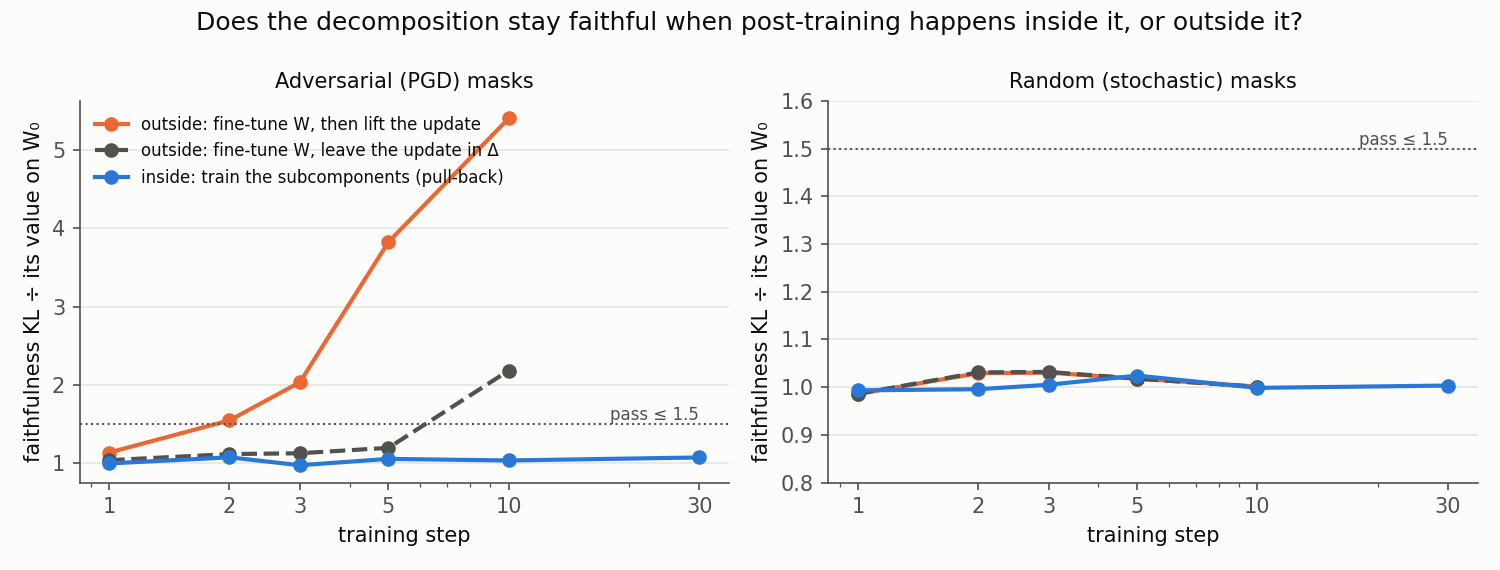

In [3]:
display(Image(E / 'lift_test/figures/inside_vs_outside.png', width=900))

**What we can take away.**
- The pull-back stays at a ratio of 0.97–1.07 throughout. The lift climbs to 5.4 by step 10.
- So on generic text, training the subcomponents keeps the decomposition faithful, and translating a finished fine-tune onto them does not.
- This says nothing about the trigger. There the pull-back's CI-masked model gives P(o) 0.64 against the trained model's 0.996 (section 4).

## 3. Identity test: how many subcomponent changes does it take to account for the pull-back's gain?

- **Measures:** the fraction of the gain in log-odds of `o` that disappears from the *target model* when subcomponents are reset to their W₀ values (u, v). 0 = none of the gain lost, 1 = all of it.
- **Held fixed:** the trained state (pull-back at step 10 or 30, or a lift matched to it in weight norm).
- **Varied:** k, the number of subcomponents reset (x-axis). They are reset in order of their single-reset drop: the fall in log-odds when that subcomponent alone is reset.
- **Blind to:** subcomponents that matter only jointly. The ranking uses single resets.

If a few subcomponents carried the update, the curve would reach about 1 at small k. The lift curves end below 1 even with every subcomponent reset, because part of a lifted update stays in Δ.

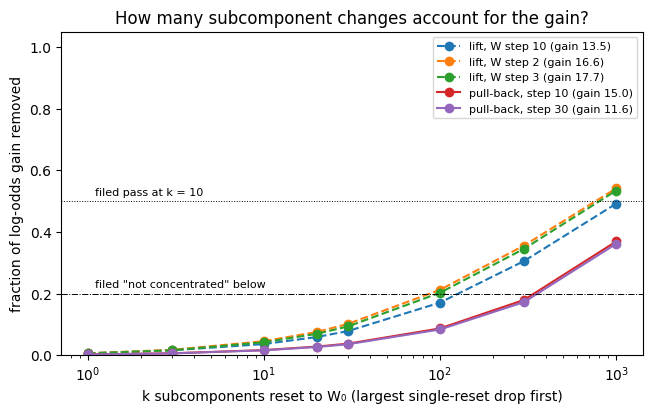

,k=1,k=10,k=100,k=1000,k=all,gain,largest single-reset drop
"lift, W step 10",0.006,0.036,0.170,0.492,0.573,13.508,0.078
"lift, W step 2",0.006,0.045,0.212,0.541,0.726,16.643,0.100
"lift, W step 3",0.006,0.042,0.202,0.534,0.700,17.688,0.100
"pull-back, step 10",0.002,0.016,0.087,0.369,1.000,15.040,0.032
"pull-back, step 30",0.002,0.016,0.083,0.361,1.000,11.615,0.024


In [4]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
lab = {'pullback_s10': 'pull-back, step 10', 'pullback_s30': 'pull-back, step 30', 'lift_s2': 'lift, W step 2',
       'lift_s3': 'lift, W step 3', 'lift_s10': 'lift, W step 10'}
for st, d in ident['states'].items():
    fr = {int(k): v for k, v in d['fraction_removed'].items() if k != 'all'}
    ks = sorted(fr)
    ax.plot(ks, [fr[k] for k in ks], marker='o', ls='-' if 'pull' in st else '--', label=f"{lab[st]} (gain {d['log_odds']['gain']:.1f})")
ax.axhline(0.5, color='k', lw=0.7, ls=':'); ax.text(1.1, 0.52, 'filed pass at k = 10', fontsize=8)
ax.axhline(0.2, color='k', lw=0.7, ls='-.'); ax.text(1.1, 0.22, 'filed "not concentrated" below', fontsize=8)
ax.set_xscale('log'); ax.set_xlabel('k subcomponents reset to W₀ (largest single-reset drop first)')
ax.set_ylabel('fraction of log-odds gain removed')
ax.set_title('How many subcomponent changes account for the gain?'); ax.legend(fontsize=8); ax.set_ylim(0, 1.05)
plt.show()
pd.DataFrame({lab[st]: {**{f'k={k}': d['fraction_removed'][k] for k in ['1', '10', '100', '1000', 'all']},
                       'gain': d['log_odds']['gain'], 'largest single-reset drop': d['revert_one_top50'][0]['drop']}
              for st, d in ident['states'].items()}).T

**What we can take away.**
- **The pull-back's change is spread thinly.** Resetting the top 10 removes 1.6% of the gain, and the top 1 000 remove 36%. The largest single drop is 0.02–0.03 log-odds against a gain of 11–15.
- **The lift is about 2.5× more concentrated at matched weight norm** (top 100 remove 0.20–0.21, against 0.08–0.09), but it is still spread.
- **The six labelled subcomponents are not among the top 10 of any state** (next cell).

In [5]:
d = ident['states']['pullback_s30']
print('any labelled subcomponent in the top 10 of any state:', any(v['sibling_in_top10'] for v in ident['states'].values()))
pd.DataFrame(d['groups']['siblings'])[['key', 'revert_drop', 'scale', 'rel_change', 'r_self', 'keeps_identity']]

any labelled subcomponent in the top 10 of any state: False


,key,revert_drop,scale,rel_change,r_self,keeps_identity
0,h.2.mlp.down_proj:2359,0.006,1.000,0.007,0.998,True
1,h.2.mlp.down_proj:1672,0.005,1.000,0.007,0.998,True
2,h.2.mlp.down_proj:2623,0.004,1.000,0.007,0.997,True
3,h.2.mlp.down_proj:3290,0.005,1.000,0.007,0.997,True
4,h.2.mlp.down_proj:3327,0.008,1.001,0.007,0.996,True
5,h.2.mlp.down_proj:3382,0.006,1.000,0.007,0.996,True


### Did the subcomponents that changed most stay the same subcomponents? (And can the check tell?)

A subcomponent **keeps identity** if all three hold:
- **r_self ≥ 0.9**: its activation x·v over Pile and the windows correlates at least 0.9 with its W₀ activation.
- **rank 1**: among all alive subcomponents of its matrix, it is still the closest match to its W₀ self.
- **write cosine**: the effect of ablating it points the same way as at W₀, within 0.1 of a split-half noise floor.

- **Measures:** r_self (y-axis) and the relative change ‖u vᵀ − u₀ v₀ᵀ‖ / ‖u₀ v₀ᵀ‖ (x-axis), for each subcomponent.
- **Held fixed:** the pull-back state at step 30.
- **Varied:** the group. *Selected* = the 20 largest single-reset drops. *Random* = one low-drop subcomponent from each of the same matrices, a group that should not change. *Labelled* = 2359 and its five siblings.
- **Blind to:** changes as small as these. Section 4 adds synthetic edits that the check should catch.

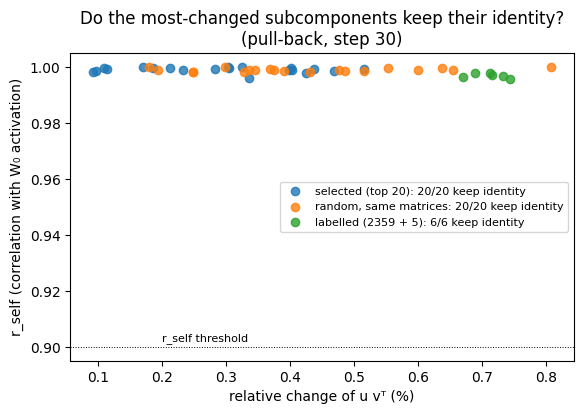

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for g, name, c in [('selected', 'selected (top 20)', 'C0'), ('null', 'random, same matrices', 'C1'), ('siblings', 'labelled (2359 + 5)', 'C2')]:
    df = pd.DataFrame(d['groups'][g])
    ax.scatter(df.rel_change * 100, df.r_self, c=c, label=f"{name}: {int(df.keeps_identity.sum())}/{len(df)} keep identity", alpha=0.8)
ax.axhline(0.9, color='k', ls=':', lw=0.7); ax.text(0.2, 0.902, 'r_self threshold', fontsize=8)
ax.set_xlabel('relative change of u vᵀ (%)'); ax.set_ylabel('r_self (correlation with W₀ activation)')
ax.set_title('Do the most-changed subcomponents keep their identity?\n(pull-back, step 30)'); ax.legend(fontsize=8)
plt.show()

**What we can take away.**
- **Every subcomponent passes, including the random group** (r_self ≈ 0.999). The changes are 0.2–0.4%, too small for the check to fail.
- So this pass is **uninformative**. It says nothing about whether the subcomponents' interpretations survive.

## 4. Concentration test: can training only a few subcomponents learn the behaviour?

This is the pull-back recipe (Adam, 30 steps, same loss) with only some subcomponents allowed to change (the arms table at the top). The **selection score |dL/ds|** is the gradient of the training loss at W₀ with respect to a scale factor s on each subcomponent (s = 1 at W₀). The table shows the top 10 and the ranks of the labelled six.

In [7]:
display(pd.DataFrame(conc['scale_gradient']['top20']).head(10))
pd.Series(conc['scale_gradient']['sibling_ranks'], name='rank of the labelled subcomponents (of 9 881)')

,abs_grad,key
0,0.988,h.0.mlp.c_fc:1535
1,0.903,h.2.mlp.down_proj:3273
2,0.769,h.3.mlp.down_proj:1630
3,0.760,h.3.attn.o_proj:283
4,0.654,h.3.mlp.down_proj:2787
5,0.643,h.3.mlp.c_fc:1940
6,0.634,h.1.mlp.down_proj:1320
7,0.570,h.1.mlp.down_proj:3478
8,0.552,h.0.mlp.c_fc:2366
9,0.541,h.2.attn.v_proj:980


h.2.mlp.down_proj:1672    1152
h.2.mlp.down_proj:2359     127
h.2.mlp.down_proj:2623     249
h.2.mlp.down_proj:3290    1026
h.2.mlp.down_proj:3327     899
h.2.mlp.down_proj:3382      93
Name: rank of the labelled subcomponents (of 9 881), dtype: int64

Each arm's learning rate comes from a grid, by a filed rule: the smallest lr that reaches held-out P(o) ≥ 0.9 with off-target KL ≤ 2× the W fine-tune's.

- **Measures:** left, P(o) at the trigger of the *trained target model* on the held-out windows. Right, off-target damage: the KL between W₀'s and the trained model's next-token distributions at the 40 non-trigger positions of the same windows.
- **Held fixed:** recipe, data, number of steps.
- **Varied:** which subcomponents may change (one line per arm, at its selected lr), and the training step (x-axis).
- **Blind to:** damage outside the 41-token windows. Pile is covered in the next figure.

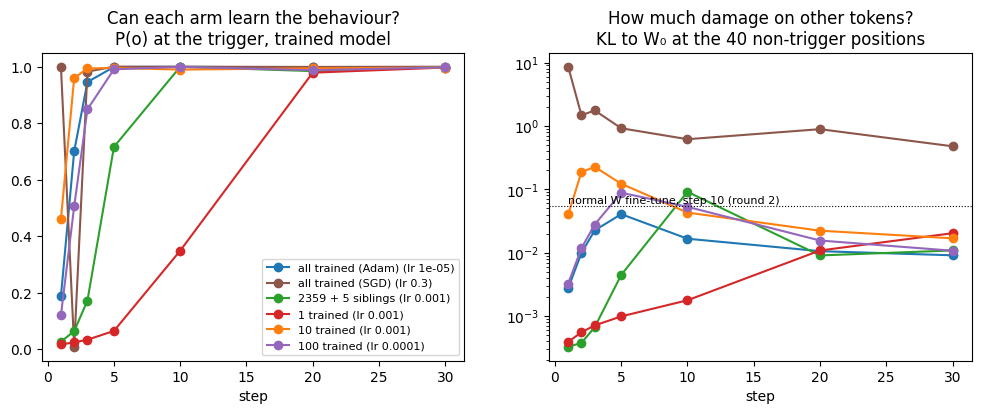

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for a, dd in ca.items():
    cur = pd.DataFrame(dd['runs'][dd['selected_lr']]['curve'])
    axes[0].plot(cur.step, cur.heldout_p_o, 'o-', c=COL[a], label=f"{ARM[a]} (lr {dd['selected_lr']})")
    axes[1].plot(cur.step, cur.heldout_kl_other, 'o-', c=COL[a])
axes[0].set_title('Can each arm learn the behaviour?\nP(o) at the trigger, trained model'); axes[0].set_xlabel('step'); axes[0].legend(fontsize=8)
axes[1].set_title('How much damage on other tokens?\nKL to W₀ at the 40 non-trigger positions'); axes[1].set_xlabel('step'); axes[1].set_yscale('log')
axes[1].axhline(0.055, color='k', ls=':', lw=0.8); axes[1].text(1, 0.06, 'normal W fine-tune, step 10 (round 2)', fontsize=8)
plt.show()

**What we can take away.**
- **Every arm learns** (P(o) ≥ 0.997 at step 30). That includes a single layer-0 subcomponent, `h.0.mlp.c_fc:1535`, and the six labelled ones.
- **Off-target damage stays small:** KL 0.011–0.020, against 0.055 for a normal W fine-tune.
- **SGD learns only at lr 0.3, with KL 0.48**, which breaks the rule. So "Adam is what spreads the change" could not be scored.

The full lr grid (final step):

In [9]:
pd.DataFrame([{'arm': ARM[a], 'lr': lr, 'P(o) held-out': r['curve'][-1]['heldout_p_o'], 'KL other positions': r['curve'][-1]['heldout_kl_other'],
               'max relative ‖δW‖': r['curve'][-1]['rel_norm_max'], 'selected': lr == dd['selected_lr']}
              for a, dd in ca.items() for lr, r in sorted(dd['runs'].items(), key=lambda t: float(t[0]))]).set_index(['arm', 'lr'])

P(o) held-out  KL other positions  max relative ‖δW‖  selected
arm                lr                                                                    
all trained (Adam) 1e-05       9.961e-01           9.100e-03          6.578e-03      True
all trained (SGD)  0.3         1.000e+00           4.775e-01          4.228e-02      True
                   1           9.937e-01           5.880e+00          1.798e-01     False
                   3           9.386e-01           7.693e+00          1.603e+00     False
                   10          1.817e-05           5.144e+00          1.385e+01     False
                   30          2.255e-02           5.654e+00          7.676e+01     False
2359 + 5 siblings  1e-05       1.551e-02           1.887e-04          7.277e-04     False
                   3e-05       2.739e-02           2.684e-04          2.123e-03     False
                   0.0001      3.078e-01           2.132e-03          7.453e-03     False
                   0.0003      9.988e-01           4.527e-02          2.082e-02     False
                   0.001       9.993e-01           1.085e-02          3.300e-02      True
1 trained          1e-05       1.302e-02           3.257e-04          4.964e-04     False
                   3e-05       1.642e-02           3.801e-04          1.472e-03     False
                   0.0001      3.443e-02           6.346e-04          4.588e-03     False
                   0.0003      3.126e-01           1.561e-03          1.311e-02     False
                   0.001       9.971e-01           2.030e-02          3.709e-02      True
10 trained         1e-05       4.865e-02           3.387e-03          1.431e-03     False
                   3e-05       4.305e-01           2.828e-02          4.230e-03     False
                   0.0001      9.854e-01           8.395e-02          8.153e-03     False
                   0.0003      9.968e-01           2.239e-02          1.250e-02     False
                   0.001       9.971e-01           1.687e-02          2.317e-02      True
100 trained        1e-05       8.784e-01           2.748e-02          3.485e-03     False
                   3e-05       9.899e-01           1.516e-02          4.364e-03     False
                   0.0001      9.978e-01           1.075e-02          8.184e-03      True
                   0.0003      9.981e-01           1.413e-02          1.623e-02     False
                   0.001       9.908e-01           4.985e-02          4.384e-02     False

### Does the decomposition still explain each trained model, on Pile and at the trigger?

**Left panel.**
- **Measures:** four faithfulness KLs between the trained target model and its component model on Pile, each divided by the same KL at W₀. The masks are: random values between the causal importance and 1 (stochastic); chosen adversarially (PGD); equal to the causal importances (CI-masked); all 1 (unmasked).
- **Varied:** the arm.
- **Noise floor:** the grey band is the spread of W₀'s PGD KL over three seeds. The filed pass threshold is 1.5.
- **Blind to:** the trigger.

**Right panel.**
- **Measures:** P(o) at the trigger of the CI-masked model. The black tick is the trained target model's P(o), the value it should match.
- **Held fixed:** Γ reads the *trained* model's activations. This is ordinary VPD usage, but Γ was trained for W₀ (section 5).
- **Varied:** the arm.
- **Positive control (filed):** with no subcomponent trained, CI-masked P(o) must stay below 0.498. It gave 0.535, so the control failed and the trigger part was not scored.

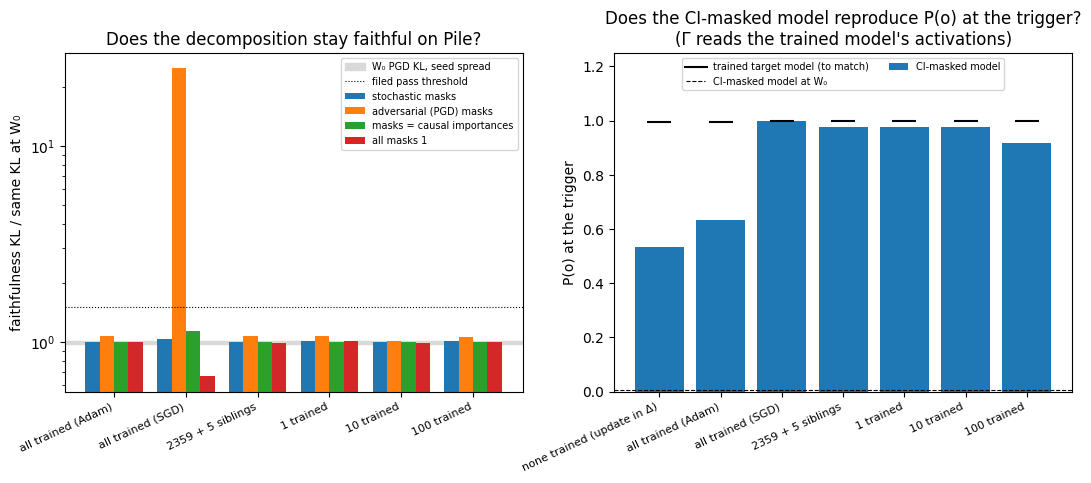

In [10]:
METRIC = {'stochastic_kl': 'stochastic masks', 'pgd_kl': 'adversarial (PGD) masks', 'ci_masked_kl': 'masks = causal importances',
          'unmasked_kl': 'all masks 1'}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
arms = list(ca)
x = np.arange(len(arms)); w = 0.2
for i, m in enumerate(METRIC):
    axes[0].bar(x + (i - 1.5) * w, [ca[a]['pile_ratios'][m] for a in arms], w, color=f'C{i}', label=METRIC[m])
pg = [v['pgd_kl'] for v in conc['pile_W0'].values()]
lo, hi = min(pg) / np.mean(pg), max(pg) / np.mean(pg)
axes[0].axhspan(lo, hi, color='0.85', zorder=0, label='W₀ PGD KL, seed spread')
axes[0].axhline(1.5, color='k', ls=':', lw=0.8, label='filed pass threshold')
axes[0].set_xticks(x, [ARM[a] for a in arms], rotation=25, ha='right', fontsize=8); axes[0].set_yscale('log')
axes[0].set_ylabel('faithfulness KL / same KL at W₀')
axes[0].set_title('Does the decomposition stay faithful on Pile?'); axes[0].legend(fontsize=7)
arms2 = ['do_nothing'] + arms
tl = {'do_nothing': conc['do_nothing_trigger_local'], **{a: ca[a]['trigger_local'] for a in arms}}
xx = np.arange(len(arms2))
axes[1].bar(xx, [tl[a]['p_o_ci'] for a in arms2], color='C0', label='CI-masked model')
axes[1].scatter(xx, [tl[a]['p_o_target'] for a in arms2], c='k', marker='_', s=300, label='trained target model (to match)')
axes[1].axhline(conc['trigger_local_W0']['p_o_ci'], color='k', ls='--', lw=0.8, label='CI-masked model at W₀')
axes[1].set_xticks(xx, [ARM[a] for a in arms2], rotation=25, ha='right', fontsize=8); axes[1].set_ylabel('P(o) at the trigger')
axes[1].set_title('Does the CI-masked model reproduce P(o) at the trigger?\n(Γ reads the trained model\'s activations)')
axes[1].set_ylim(0, 1.25); axes[1].legend(fontsize=7, loc='upper center', ncol=2)
plt.show()

**What we can take away.**
- **Pile:** every arm except SGD stays within 1.08, inside a 3.5% seed spread. SGD's PGD ratio is 24.9.
- **Trigger:** the sparse arms' CI-masked models reach P(o) 0.92–0.98. The all-subcomponent Adam arm reaches only 0.64.
- **The failed control matters most.** With *no* subcomponent trained, the CI-masked model still reaches 0.53 (0.004 at W₀). Its subcomponents are exactly W₀'s, so the only thing that changed is the activations Γ reads, and those include Δ's share of the update. So the CI-masked P(o) at the trigger can rise without any subcomponent changing. This is why amendments 1 and 2 were run.

### How much did the trained subcomponents change? (identity check, with synthetic edits it should catch)

- **Rows marked "control"** are synthetic edits of `2359` that the check should flag: v rotated by 20° or 45°, v swapped for another subcomponent's v, u replaced by a random vector.
- **The other rows** are the subcomponents the sparse arms actually trained.
- **Columns:** scale = ‖u vᵀ‖ / ‖u₀ v₀ᵀ‖; |cos u| and |cos v| against W₀; relative change; r_self; rank; write cosine and its noise floor; keeps identity.

In [11]:
cols = ['key', 'scale', 'cos_u', 'cos_v', 'rel_change', 'r_self', 'rank', 'write_cos', 'write_floor', 'keeps_identity']
ctrl = pd.DataFrame([{**v, 'key': f'control: {k}'} for k, v in conc['identity_controls'].items()])[cols]
moved = pd.concat([pd.DataFrame(ca[a]['identity']).assign(arm=ARM[a]) for a in ['top1', 'top10', 'siblings']])
display(ctrl.set_index('key'))
moved.set_index(['arm', 'key'])[cols[1:]]

,scale,cos_u,cos_v,rel_change,r_self,rank,write_cos,write_floor,keeps_identity
key,,,,,,,,,
control: random_u,1.000,0.047,1.000,1.447,1.000,1,-0.040,0.741,False
control: rot_v_20,1.000,1.000,0.940,0.347,0.942,1,0.998,0.741,True
control: rot_v_45,1.000,1.000,0.707,0.765,0.714,1,0.988,0.741,False
control: swap_v,1.409,1.000,0.050,1.687,0.003,345,0.711,0.741,False


scale  cos_u  cos_v  rel_change  r_self  rank  write_cos  write_floor  keeps_identity
arm               key                                                                                                          
1 trained         h.0.mlp.c_fc:1535       1.337  0.806  0.959       0.850   0.958     1      0.909        0.991            True
10 trained        h.0.mlp.c_fc:1535       1.029  0.954  0.991       0.335   0.991     1      0.993        0.991            True
                  h.0.mlp.c_fc:2366       1.034  0.951  0.989       0.351   0.987     1      0.770        0.923           False
                  h.1.mlp.down_proj:1320  0.991  1.000  0.992       0.129   1.000     1      0.991        0.985            True
                  h.1.mlp.down_proj:3478  1.005  0.999  0.995       0.107   1.000     1      0.983        0.974            True
                  h.2.attn.v_proj:980     1.066  0.989  0.961       0.331   0.935     1      0.908        0.897            True
                  h.2.mlp.down_proj:3273  1.132  0.948  0.971       0.444   0.966     1      0.926        0.932            True
                  h.3.attn.o_proj:283     1.016  0.995  0.987       0.191   0.992     1      0.996        0.985            True
                  h.3.mlp.c_fc:1940       1.022  0.983  0.997       0.200   0.998     1      0.989        0.936            True
                  h.3.mlp.down_proj:1630  0.993  0.996  0.989       0.173   0.965     1      0.996        0.971            True
                  h.3.mlp.down_proj:2787  1.004  0.999  1.000       0.050   0.998     1      0.992        0.999            True
2359 + 5 siblings h.2.mlp.down_proj:1672  1.400  0.721  0.927       1.043   0.652     1      0.353        0.442           False
                  h.2.mlp.down_proj:2359  1.436  0.705  0.941       1.076   0.672     1      0.633        0.741           False
                  h.2.mlp.down_proj:2623  1.436  0.718  0.941       1.060   0.636     1      0.841        0.992           False
                  h.2.mlp.down_proj:3290  1.494  0.723  0.932       1.103   0.674     1      0.857        0.984           False
                  h.2.mlp.down_proj:3327  1.538  0.743  0.921       1.123   0.642     1     -0.065        0.714           False
                  h.2.mlp.down_proj:3382  1.411  0.733  0.941       1.022   0.687     1      0.723        0.368           False

**What we can take away.**
- **The check catches edits of about 45° or more.** It flags the swap, the random u and the 45° rotation, but passes the 20° rotation.
- **The six siblings changed a lot.** Each u vᵀ moved by about 100%: scale 1.4–1.5×, |cos u| 0.70–0.74, r_self 0.64–0.69. None keeps identity. The read side v is fairly stable (|cos v| 0.92–0.94), and the write side u turned by about 45°.
- **`h.0.mlp.c_fc:1535`, trained alone,** has scale 1.34 and |cos u| 0.81, and still keeps identity.

## 5. Amendment 1: do the trained subcomponents reproduce the behaviour when the masks are W₀'s causal importances?

The question is how much of the CI-masked model's P(o) at the trigger comes from the changed subcomponents themselves, and how much from Γ outputting different causal importances.

- **Measures:** P(o) at the trigger of the CI-masked model, divided by the trained target model's P(o). 1 = fully reproduced.
- **Held fixed:** within each arm, the subcomponents (the arm's trained u, v) and the tokens.
- **Varied:** the activations Γ reads to produce the masks:
  - **blue:** the trained target model's activations (ordinary VPD, as in section 4);
  - **orange:** W₀'s activations on the same tokens. These are the causal importances the decomposition had before training.
- **Positive control:** with no subcomponent trained, orange must fall to W₀'s own value. It does (0.0045), so the measure can detect a difference.
- **Filed:** siblings and 10 trained ≥ 0.8 (A1, A2); all trained (Adam) < 0.5 (A3).
- **Blind to:** whether either set of causal importances is correct for the trained model. Γ was trained for W₀ only. Orange is out of date by construction. Blue is Γ applied outside the model it was trained for, and nothing has checked it.

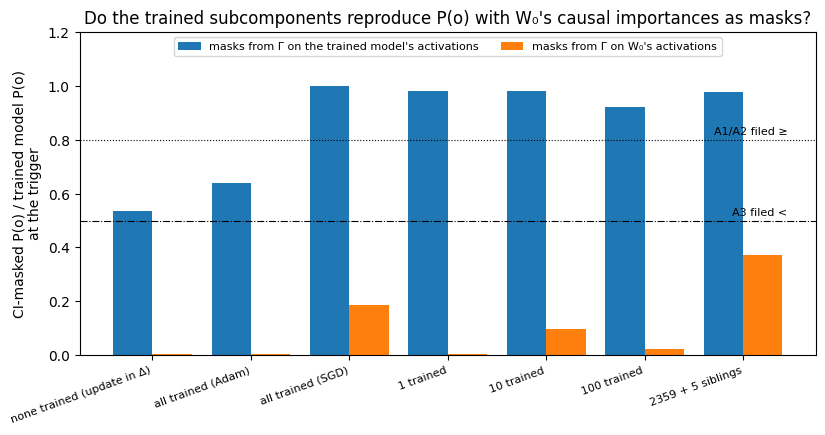

,masks from trained model's activations,masks from W₀'s activations,"KL at trigger, W₀'s masks"
none trained (update in Δ),0.537,0.004,5.731
all trained (Adam),0.637,0.006,5.379
all trained (SGD),0.999,0.188,2.075
1 trained,0.980,0.005,5.647
10 trained,0.980,0.097,2.867
100 trained,0.920,0.024,4.152
2359 + 5 siblings,0.979,0.371,1.570


In [12]:
arms_a = ['do_nothing', 'adam_all', 'sgd_all', 'top1', 'top10', 'top100', 'siblings']
sg = {'do_nothing': am1['do_nothing_state_gated'], **{a: am1['arms'][a]['state_gated'] for a in arms_a[1:]}}
wg = {'do_nothing': am1['do_nothing_w0_gated'], **{a: am1['arms'][a]['w0_gated'] for a in arms_a[1:]}}
x = np.arange(len(arms_a))
fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.bar(x - 0.2, [sg[a]['p_o_ci'] / sg[a]['p_o_target'] for a in arms_a], 0.4, color='C0',
       label="masks from Γ on the trained model's activations")
ax.bar(x + 0.2, [wg[a]['p_o_ci'] / wg[a]['p_o_target'] for a in arms_a], 0.4, color='C1',
       label="masks from Γ on W₀'s activations")
ax.axhline(0.8, color='k', ls=':', lw=0.8); ax.text(6.45, 0.82, 'A1/A2 filed ≥', fontsize=8, ha='right')
ax.axhline(0.5, color='k', ls='-.', lw=0.8); ax.text(6.45, 0.52, 'A3 filed <', fontsize=8, ha='right')
ax.set_xticks(x, [ARM[a] for a in arms_a], rotation=20, ha='right', fontsize=8)
ax.set_ylabel('CI-masked P(o) / trained model P(o)\nat the trigger')
ax.set_title("Do the trained subcomponents reproduce P(o) with W₀'s causal importances as masks?")
ax.set_ylim(0, 1.2); ax.legend(fontsize=8, loc='upper center', ncol=2)
plt.show()
pd.DataFrame({ARM[a]: {"masks from trained model's activations": sg[a]['p_o_ci'] / sg[a]['p_o_target'],
                       "masks from W₀'s activations": wg[a]['p_o_ci'] / wg[a]['p_o_target'],
                       "KL at trigger, W₀'s masks": wg[a]['kl_trigger_ci']} for a in arms_a}).T

**What we can take away.**
- **With W₀'s causal importances as masks, the trained subcomponents reproduce little of the behaviour:** 0.005 (1 trained), 0.10 (10 trained), 0.37 (siblings). A1 and A2 are reversed.
- **This is not because the trained subcomponents are masked out.** At the trigger their W₀ causal importances are already 0.83–0.93 (next cell). `h.0.mlp.c_fc:1535` has causal importance 0.89, and its change alone gives 0.005.
- **So, in the CI-masked model, the behaviour appears only when the masks change.**
- **What this does *not* show:** that the trained model needs a different set of subcomponents at the trigger. The masks that work (blue) come from a Γ that has not been checked for the trained model. With no subcomponent trained, blue alone reaches 0.54 of the target, so Γ reacting to changed activations explains at least part of the effect. Telling the two apart needs causal importances checked for the trained model (Not run).

In [13]:
pd.concat([pd.DataFrame(am1['arms'][a]['moved']).assign(arm=ARM[a]) for a in ['top1', 'siblings']]).set_index(['arm', 'key']) \
  .rename(columns={'g_trigger_W0': "causal importance at the trigger, W₀'s activations"})

causal importance at the trigger, W₀'s activations
arm               key                                                                       
1 trained         h.0.mlp.c_fc:1535                                                   0.894 
2359 + 5 siblings h.2.mlp.down_proj:1672                                              0.881 
                  h.2.mlp.down_proj:2359                                              0.908 
                  h.2.mlp.down_proj:2623                                              0.831 
                  h.2.mlp.down_proj:3290                                              0.862 
                  h.2.mlp.down_proj:3327                                              0.917 
                  h.2.mlp.down_proj:3382                                              0.928

## 6. Amendment 2: whose causal importance rises at the trigger, and is it the same subcomponents for every arm?

Definitions used in this section:
- **Rise in causal importance** of a subcomponent: its causal importance at the trigger when Γ reads the trained model's activations, minus its value when Γ reads W₀'s, averaged over the 73 held-out windows.
- **S_rise(t)**: the subcomponents whose rise exceeds t. The main threshold is t = 0.3. Nearly all of them had causal importance ≈ 0 at W₀.

### Does raising only S_rise's causal importances reproduce the effect?

- **Measures:** recovery = (lo(mixed) − lo(W₀'s)) / (lo(trained) − lo(W₀'s)). Here lo is the CI-masked model's log-odds of `o` at the trigger under three sets of masks:
  - **trained:** all masks from Γ on the trained model's activations;
  - **W₀'s:** all masks from Γ on W₀'s activations;
  - **mixed:** the trained-activation masks for S_rise and W₀'s masks everywhere else.

  0 = no better than W₀'s masks, 1 = as good as all trained-activation masks.
- **Held fixed:** each arm's trained subcomponents. Δ is excluded.
- **Varied:** the threshold t (x-axis) and the arm (line).
- **Negative control (×):** a random set of the same size from the same matrices, all with rise < 0.05.
- **Blind to:** the same as section 5: both sets of masks come from the old Γ.

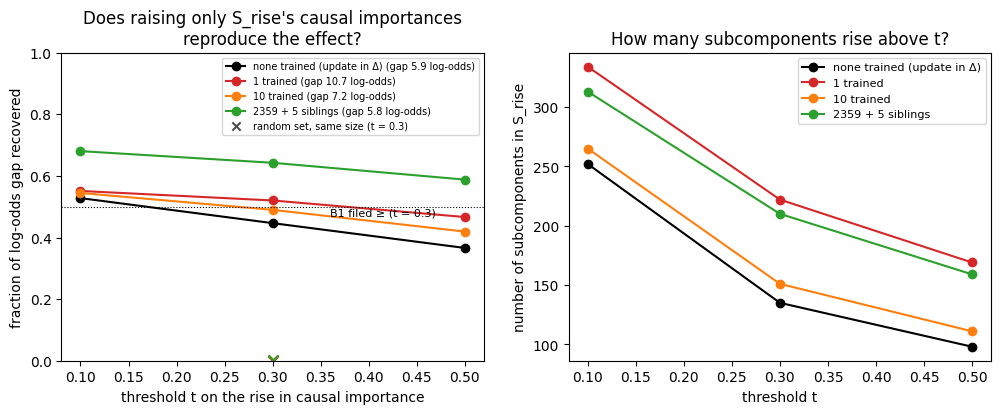

In [14]:
arms_b = ['do_nothing', 'top1', 'top10', 'siblings']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for a in arms_b:
    r = am2['arms'][a]['recovery']
    axes[0].plot([float(t) for t in r], list(r.values()), 'o-', c=COL[a], label=f"{ARM[a]} (gap {am2['arms'][a]['gap']:.1f} log-odds)")
    axes[0].scatter([0.3], [am2['arms'][a]['recovery_random_control']], c=COL[a], marker='x', s=50)
axes[0].scatter([], [], c='0.3', marker='x', label='random set, same size (t = 0.3)')
axes[0].axhline(0.5, color='k', ls=':', lw=0.8); axes[0].text(0.36, 0.47, 'B1 filed ≥ (t = 0.3)', fontsize=8)
axes[0].set_xlabel('threshold t on the rise in causal importance'); axes[0].set_ylabel('fraction of log-odds gap recovered')
axes[0].set_ylim(0, 1); axes[0].set_title('Does raising only S_rise\'s causal importances\nreproduce the effect?')
axes[0].legend(fontsize=7)
for a in arms_b:
    n = am2['arms'][a]['n_on']
    axes[1].plot([float(t) for t in n], list(n.values()), 'o-', c=COL[a], label=ARM[a])
axes[1].set_xlabel('threshold t'); axes[1].set_ylabel('number of subcomponents in S_rise')
axes[1].set_title('How many subcomponents rise above t?'); axes[1].legend(fontsize=8)
plt.show()

**What we can take away.**
- **About half.** At t = 0.3, S_rise (135–222 subcomponents, depending on the arm) recovers 0.45 (none trained), 0.52 (1 trained), 0.49 (10 trained) and 0.64 (siblings). B1 needed ≥ 0.5 in three arms, so it **fails narrowly**.
- **The particular set matters.** A random set of the same size recovers 0.0005–0.0016.
- **The rest is spread out.** Lowering t to 0.1 raises recovery to only 0.53–0.68.

### Do different arms raise the causal importance of the same subcomponents?

- **Measures:** Jaccard overlap |A ∩ B| / |A ∪ B| of S_rise(0.3) between two arms.
- **Caveat:** "none trained" and "all trained (Adam)" share a target model and hence Γ's input, so their overlap of 1.0 holds by construction. The informative pairs involve 1 trained, 10 trained or siblings.

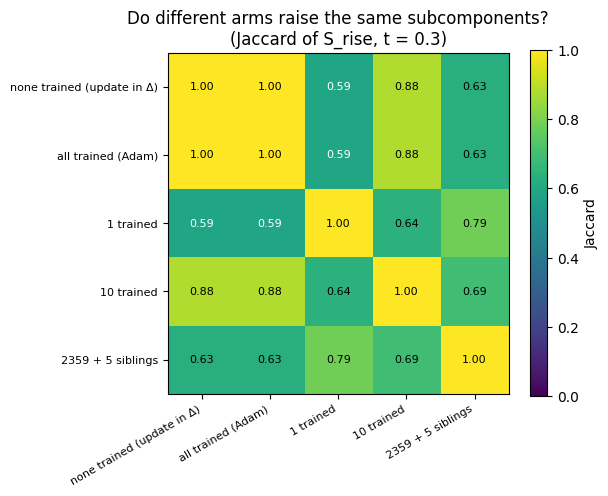

In [15]:
names = ['do_nothing', 'adam_all', 'top1', 'top10', 'siblings']
J = pd.DataFrame(np.eye(len(names)), index=[ARM[n] for n in names], columns=[ARM[n] for n in names])
for k, v in am2['jaccard'].items():
    a, b = k.split('|'); J.loc[ARM[a], ARM[b]] = J.loc[ARM[b], ARM[a]] = v
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(J.values, vmin=0, vmax=1, cmap='viridis')
ax.set_xticks(range(len(names)), J.columns, rotation=30, ha='right', fontsize=8); ax.set_yticks(range(len(names)), J.index, fontsize=8)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f'{J.values[i, j]:.2f}', ha='center', va='center', color='w' if J.values[i, j] < 0.6 else 'k', fontsize=8)
ax.set_title('Do different arms raise the same subcomponents?\n(Jaccard of S_rise, t = 0.3)'); plt.colorbar(im, label='Jaccard')
plt.show()

**What we can take away.**
- **Largely the same set.** Overlaps are 0.59–0.88 across the informative pairs (B2 needed ≥ 0.3). Training one layer-0 subcomponent and training the six layer-2 siblings raise sets that overlap 0.79.
- **Caveat:** a shared set could reflect how the old Γ responds to the activation shift at the trigger, not something about the trained models.

The table shows the subcomponents with the largest rise, and how many arms list each among their 25 largest. Only the top 25 per arm were saved, so this is a lower bound on the overlap.

In [16]:
seen = defaultdict(dict)
for a in arms_b:
    for t in am2['arms'][a]['top_on']:
        seen[t['key']][ARM[a]] = round(t['dg'], 2)
core = pd.DataFrame(seen).T
core.insert(0, 'n arms', core.notna().sum(1))
core.sort_values('n arms', ascending=False).head(20)

,n arms,none trained (update in Δ),1 trained,10 trained,2359 + 5 siblings
h.2.attn.o_proj:858,4,1.00,1.00,1.00,1.00
h.3.mlp.down_proj:2102,4,1.00,1.00,1.00,1.00
h.3.mlp.down_proj:3273,4,0.99,1.00,1.00,1.00
h.3.mlp.c_fc:1449,4,0.99,0.99,0.99,0.99
h.0.mlp.down_proj:1914,4,0.99,1.00,1.00,1.00
h.2.mlp.down_proj:1844,4,0.98,0.99,1.00,0.99
h.2.attn.o_proj:132,4,0.97,0.99,1.00,1.00
h.3.mlp.down_proj:1037,4,0.97,0.99,0.99,1.00
h.2.mlp.down_proj:2550,4,0.97,1.00,1.00,1.00
h.3.mlp.c_fc:191,4,0.97,0.99,0.99,0.99


### At W₀, does each subcomponent in S_rise already push towards `o`?

Unlike sections 5–6 above, this measurement is made entirely at W₀, so it does not depend on Γ reading changed activations.

- **Measures:** the change in the CI-masked model's log-odds of `o` at the trigger when one subcomponent's mask is set to 1 at every position.
- **Held fixed:** W₀'s target model, W₀'s subcomponents, and W₀'s causal importances as all other masks.
- **Varied:** which subcomponent is set to 1. Either one from the union of S_rise over arms (244), or one of 300 random alive subcomponents whose causal importance does not rise in any arm.
- **Filed (B3):** mean over S_rise > random mean + 3 SE, and > 0.

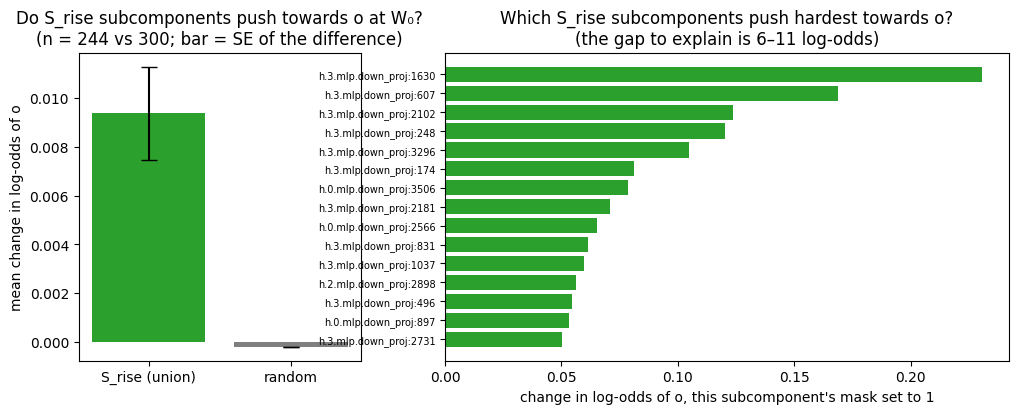

frac_null_positive    5.400e-01
frac_on_positive      6.311e-01
mean_null            -1.877e-04
mean_on               9.375e-03
median_null           1.860e-05
median_on             2.011e-03
n_null                3.000e+02
n_on                  2.440e+02
se_diff               1.901e-03
dtype: float64

In [17]:
so = am2['switch_on']
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [1, 2]})
axes[0].bar(['S_rise (union)', 'random'], [so['mean_on'], so['mean_null']], yerr=[so['se_diff'], 0], color=['C2', 'C7'], capsize=6)
axes[0].set_ylabel('mean change in log-odds of o'); axes[0].set_title(f"Do S_rise subcomponents push towards o at W₀?\n(n = {so['n_on']} vs {so['n_null']}; bar = SE of the difference)")
top = pd.DataFrame(so['top_on'])
axes[1].barh(top.key[::-1], top.effect[::-1], color='C2'); axes[1].set_xlabel('change in log-odds of o, this subcomponent\'s mask set to 1')
axes[1].set_title('Which S_rise subcomponents push hardest towards o?\n(the gap to explain is 6–11 log-odds)')
axes[1].tick_params(axis='y', labelsize=7)
plt.show()
pd.Series({k: v for k, v in so.items() if k != 'top_on'})

**What we can take away.**
- **B3 passes, but the effect is small.** The mean push is +0.0094 log-odds against −0.0002 for random subcomponents, about 5 SE apart. 63% of S_rise push positive, against 54% of the random set.
- **No single subcomponent writes `o`.** The strongest single push is 0.23 (`h.3.mlp.down_proj:1630`), against a gap of 6–11.
- So the subcomponents whose causal importance rises are, at W₀, slightly biased towards `o`. They are not an existing `o` circuit waiting to be switched on.

## 7. Reading the four 10-15 runs together

- **Established:** a few subcomponents can learn the behaviour with little damage elsewhere (section 4). The all-subcomponent pull-back spreads its change too thinly for our identity check to see (section 3). Faithfulness on Pile survives every Adam arm (section 4).
- **Established, but only about the old Γ:** at the trigger, the CI-masked model reproduces the behaviour only when Γ reads the trained model's activations. The subcomponents whose causal importance rises are largely shared across arms and recover about half the gap (sections 5–6).
- **Not established:** that the update "recruits pre-existing subcomponents" or reveals an existing capability. The masks that reproduce the behaviour come from a Γ that was never checked for the trained model. Raising causal importances alone, with no subcomponent trained, already reaches 0.54 of the target.
- **Weak independent support:** measured purely at W₀, the risen subcomponents push slightly towards `o` (section 6, last figure).

## Look up one subcomponent

`component(key)` gathers everything the 10-15 runs recorded about one subcomponent: single-reset drops, identity statistics, |dL/ds| rank, causal importances and their rise, and the push towards `o` at W₀. A missing entry means the subcomponent was not in the saved top lists. Edit the key and re-run.

In [18]:
def component(key):
    out = {}
    for st, d in ident['states'].items():
        for t in d['revert_one_top50']:
            if t['key'] == key: out[f'identity {st}: single-reset drop'] = t['drop']
        for g in ('selected', 'null', 'siblings'):
            for t in d['groups'][g]:
                if t['key'] == key:
                    out.update({f'identity {st} ({g}): {m}': t[m] for m in ('rel_change', 'scale', 'r_self', 'keeps_identity')})
    for i, t in enumerate(conc['scale_gradient']['top20']):
        if t['key'] == key: out['|dL/ds| rank'] = i + 1
    if key in conc['scale_gradient']['sibling_ranks']: out['|dL/ds| rank'] = conc['scale_gradient']['sibling_ranks'][key]
    for a, d in ca.items():
        for t in d['identity']:
            if t['key'] == key: out.update({f'{ARM[a]}, trained: {m}': t[m] for m in ('scale', 'cos_u', 'cos_v', 'r_self', 'keeps_identity')})
        for t in d['revert_one_top20']:
            if t['key'] == key: out[f'{ARM[a]}: single-reset drop'] = t['drop']
    for a in ('top1', 'top10', 'top100', 'siblings'):
        for t in am1['arms'][a]['moved']:
            if t['key'] == key: out[f"{ARM[a]}: causal importance at trigger, W₀'s activations"] = t['g_trigger_W0']
    for a, d in am2['arms'].items():
        for t in d['top_on']:
            if t['key'] == key: out[f"{ARM[a]}: rise in causal importance at trigger (value at W₀)"] = f"{t['dg']:.2f} ({t['g_W0']:.2f})"
    for t in so['top_on']:
        if t['key'] == key: out['push towards o at W₀ (mask set to 1)'] = t['effect']
    return pd.Series(out, name=key, dtype=object)

display(component('h.2.attn.o_proj:858'))
component('h.0.mlp.c_fc:1535')

all trained (Adam): rise in causal importance at trigger (value at W₀)            1.00 (0.00)
none trained (update in Δ): rise in causal importance at trigger (value at W₀)    1.00 (0.00)
2359 + 5 siblings: rise in causal importance at trigger (value at W₀)             1.00 (0.00)
1 trained: rise in causal importance at trigger (value at W₀)                     1.00 (0.00)
10 trained: rise in causal importance at trigger (value at W₀)                    1.00 (0.00)
Name: h.2.attn.o_proj:858, dtype: object

identity lift_s2: single-reset drop                             0.029
identity pullback_s10: single-reset drop                        0.016
identity pullback_s10 (selected): rel_change                    0.002
identity pullback_s10 (selected): scale                         0.999
identity pullback_s10 (selected): r_self                          1.0
identity pullback_s10 (selected): keeps_identity                 True
identity pullback_s30: single-reset drop                        0.011
identity pullback_s30 (selected): rel_change                    0.003
identity pullback_s30 (selected): scale                           1.0
identity pullback_s30 (selected): r_self                          1.0
identity pullback_s30 (selected): keeps_identity                 True
|dL/ds| rank                                                        1
all trained (Adam), trained: scale                                1.0
all trained (Adam), trained: cos_u                                1.0
all trained (Adam), 

## Not run

- **Causal importances checked for the trained model.** The question left open by sections 5–6. It needs either a Γ retrained (or fine-tuned) on the trained model, or a test that the subcomponents Γ marks unimportant at the trigger can be ablated without changing the trained model's output. Each is a new measurement and goes through `/design` first.
- **What the S_rise subcomponents do elsewhere.** Their top-activating contexts at W₀ were not looked at.
- **The other half of the gap** in section 6: many small rises, or something else.
- **Whether Adam is what spreads the change.** SGD needs a finer lr grid (0.03–0.3) or momentum to be scorable.
- **The siblings arm at matched ‖δW‖.** It moves 5× further than the all-subcomponent Adam arm (relative norm 0.033 against 0.0066).
- **Training Γ along with the subcomponents** (round-4 backlog).
- **The open worry,** "LoRA inherently noisy vs VPD inherently misses structure". It is in `backlog.md` and needs its own `/design`.
- **Scope:** other behaviours, more than 30 steps, and a behaviour the model lacks.